# Homogeneous correlation clustering (cluster shrinkage)
**ARPM script:** `s_shrink_corr_hom_clusters` · **Lab:** Correlation clustering

**In plain words:** a 500×500 correlation matrix has ~125k numbers, most of them noise.
If we trust the clusters, replace every correlation **inside** a cluster by that cluster's average,
and every correlation **between** two clusters by their cross-average. Few parameters, much less noise: a shrinkage estimator.
If the result isn't a valid correlation matrix (an eigenvalue ≤ 0), shrink the off-diagonals towards 0 by $\gamma$ until it is.

Example: 5 stocks, clusters {0,1} and {2,3,4} (`l_clus = [0, 2, 5]`).

Changes from ARPM's original: data path via `clustering_lab.paths`. Code otherwise unchanged.

> **Watch the inner loop:** `for k2 in range(k1, k_bar)` starts at `k1`, so the within-block value is overwritten by the
> plain block average *including the 1s on the diagonal*. The cross-check cell at the bottom shows the difference vs the
> off-diagonal average that the first line of the loop intends.

In [11]:
# --- PyCharm plumbing (not ARPM code) -------------------------------------
# Find the unit root from wherever the notebook runs, so `clustering_lab`
# imports and the data path work in PyCharm, Jupyter or a test run.
import sys
from pathlib import Path

UNIT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "clustering_lab").is_dir())
if str(UNIT_ROOT) not in sys.path:
    sys.path.insert(0, str(UNIT_ROOT))

from clustering_lab.paths import stocks_csv_path, OUTPUTS_DIR
STOCKS_CSV = stocks_csv_path()   # data/db_stocks_sp.csv (or $ARPM_DB_STOCKS_SP)
print("data:", STOCKS_CSV)

data: C:\Dev\Projects\ARPM\probabilistic_machine_learning\unit3_autoencoders_graphical_clustering\data\db_stocks_sp.csv


In [12]:
import pandas as pd
from numpy import isnan, where
from numpy import argsort, array, average, corrcoef, diag, diagflat, \
                  diff, eye, ix_, log, ones, sum, zeros
from numpy.linalg import det, eigvalsh
from pandas import read_csv
from seaborn import heatmap
from matplotlib.pyplot import show, xticks, yticks

## Load data

In [13]:
# loading db_stocks_sp.csv
# csv has 2 header rows (sector on top, then ticker underneath)
# index_col = 0 (the first column 'dates' becomes the row labels
db_stocks_sp = read_csv(STOCKS_CSV, index_col=0, header=[0, 1])
# stocks values
v = array(db_stocks_sp)

# get the number of columns/stocks
n_bar = v.shape[1]
# get the list of distinct sectors names
sectors = array(db_stocks_sp.columns.levels[0])
# sectors indices - getting the integer value for each stock
labels = array(db_stocks_sp.columns.codes)[0, :]

## 1. Compute correlation matrix of log-returns

In [5]:
# the daily log-returns (lnVt - lnVt-1)
eps = diff(log(v), axis=0)
# getting the historical correlation of every pair of stocks
# .T(transpose) is needed because corrcoef() treats rows as the variables and our stocks are in column format.
c2_hist = corrcoef(eps.T)

# sorting/grouping index for sectors together (Energy, Financials,...)
i_s = argsort(labels)
# correlation matrix/shuffled by the same groupings of sectors above (using 'ix_(...)')
c2_sec = c2_hist[ix_(i_s, i_s)]

In [7]:
# ---- data check (my addition, not ARPM) ----
print("prices:", v.shape, " (days × stocks)")
print("returns:", eps.shape, " correlation:", c2_hist.shape)
print("NaNs in prices:", int(isnan(v).sum()), " NaNs in correlation:", int(isnan(c2_hist).sum()))
print("dates:", db_stocks_sp.index[0], "→", db_stocks_sp.index[-1])
print("\nstocks per sector:")
print(pd.Series(labels).value_counts().sort_index().set_axis(sectors).to_string())

same = labels[:, None] == labels[None, :]
off = ~eye(n_bar, dtype=bool)
print(f"\navg correlation, same sector:      {c2_hist[same & off].mean():.3f}")
print(f"avg correlation, different sector: {c2_hist[~same].mean():.3f}")

prices: (1600, 392)  (days × stocks)
returns: (1599, 392)  correlation: (392, 392)
NaNs in prices: 0  NaNs in correlation: 0
dates: 2006-07-31 → 2012-12-05

stocks per sector:
ConsumerDiscretionary        61
ConsumerStaples              35
Energy                       32
Financials                   65
HealthCare                   40
Industrials                  53
InformationTechnology        48
Materials                    26
TelecommunicationServices     4
Utilities                    28

avg correlation, same sector:      0.553
avg correlation, different sector: 0.454


## 2. Perform homogeneous correlation cluster shrinkage

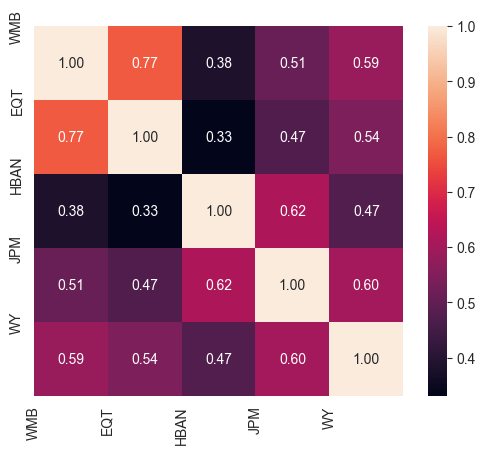

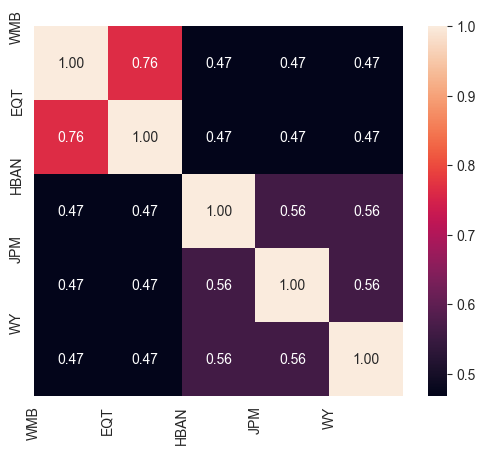

In [14]:
# entries of interest (I can change these values)
index = [96, 97, 128, 132, 138]
# cuts a 5x5 slice of the sector-sorted correlation matrix
c2_bar = c2_sec[ix_(index, index)]

# compute optimal clustering for matrix c2_bar
i_clus = range(len(index))
# creating a copy of the same 5x5 sector-sorted correlation matrix as created above
c2_c = c2_bar[ix_(i_clus, i_clus)]

# Defining the clusters
# homogenize correlation using views
# vector such that l_hom(k+1):l_hom[k], vector of entries in k-th cluster (I can change this...)
# cluster boundaries
l_clus = [0, 2, 5]
# 2 clusters
k_bar = len(l_clus) - 1
# sizes: [2, 3]
l_diff = diff(l_clus)
#
c2_clus = zeros((len(i_clus), len(i_clus)))
# threshold for determinant equal to zero (you can change it)
threshold = 10**-5
# shrinkage coefficient to ensure positivity (you can change it)
gamma = 1
# routine step (you can change it)
step = 0.005

# The averaging loop
for k1 in range(k_bar):
    # rows of cluster k1
    d = range(l_clus[k1], l_clus[k1 + 1])
    # its size
    b = l_diff[k1]
    if b > 1:
        # avg off-diagonal correlation
        c2_tmp = sum(c2_c[ix_(d, d)] - eye(b))/(b*(b - 1))
        c2_clus[ix_(d, d)] = c2_tmp*ones((b, b))
    # updated to produce the correct averages
    for k2 in range(k1 + 1, k_bar):
        d1 = range(l_clus[k2], l_clus[k2 + 1])
        # avg of block between k1 and k2
        c2_tmp = average(c2_c[ix_(d, d1)])
        b1 = l_diff[k2]
        c2_clus[ix_(d, d1)] = c2_tmp*ones((b, b1))
        c2_clus[ix_(d1, d)] = c2_tmp*ones((b1, b))
        # putting 1's back on the main diagonals
        c2_clus = c2_clus - diagflat(diag(c2_clus)) + diagflat(ones((1, len(i_clus))))
        c2_hom = c2_clus


# ensure positivity
# smaller eigenvalues computation (smallest eigenvalue)
lam_min = min(eigvalsh(c2_hom))
while lam_min <= threshold:
        # 1 -> 0.995 -> 0.990...
        gamma = gamma - step
        # homogenized correlation matrix
        # shrink off-diagonals towards 0
        c2_hom = gamma*c2_hom
        # 1 on main diagonals
        c2_hom = c2_hom - diagflat(diag(c2_hom)) + diagflat(ones((1, len(i_clus))))
        # smallest eigenvalue update
        lam_min = min(eigvalsh(c2_hom))
        if gamma <= 0:
            print('convergence not reached')

############################################### plots ###############################################
use_symbols = True  # True to use stocks symbols as labels, False to use sectors (you can change it)
if use_symbols:
    ticks_labels = array([k for j,k in db_stocks_sp.columns.values])
else:
    ticks_labels = array([j for j,k in db_stocks_sp.columns.values])
# Align names with the sector sorted matrix (c2_sec)
ticks_labels = ticks_labels[i_s]

# starting correlation
heatmap(c2_bar, square=True, annot=True, fmt='.2f')
xticks(i_clus, ticks_labels[index], rotation=90); yticks(i_clus, ticks_labels[index]); show();

# homogenized correlation
heatmap(c2_hom, square=True, annot=True, fmt='.2f')
xticks(i_clus, ticks_labels[index], rotation=90); yticks(i_clus, ticks_labels[index]); show();

## Cross-check with `clustering_lab` (not ARPM code)
`homogenize_correlation` uses the **off-diagonal** average inside each block. Compare with ARPM's matrix above.
(Note also: ARPM's tick labels index the *unsorted* column list with `index`, while `c2_bar` comes from the *sector-sorted* matrix, so the tickers shown may not be the stocks plotted. `ticks_labels[i_s][index]` would be the matching names.)

In [15]:
from clustering_lab.corr_cluster_tools import homogenize_correlation

c2_hom_lab, gamma_lab = homogenize_correlation(c2_bar, l_clus)
print("ARPM loop:\n", c2_hom.round(3))
print("\nclustering_lab (off-diagonal block averages), gamma =", round(gamma_lab, 3), ":\n", c2_hom_lab.round(3))
print("\nstocks actually plotted:", ticks_labels[index])

ARPM loop:
 [[1.    0.765 0.468 0.468 0.468]
 [0.765 1.    0.468 0.468 0.468]
 [0.468 0.468 1.    0.562 0.562]
 [0.468 0.468 0.562 1.    0.562]
 [0.468 0.468 0.562 0.562 1.   ]]

clustering_lab (off-diagonal block averages), gamma = 1.0 :
 [[1.    0.768 0.471 0.471 0.471]
 [0.768 1.    0.471 0.471 0.471]
 [0.471 0.471 1.    0.564 0.564]
 [0.471 0.471 0.564 1.    0.564]
 [0.471 0.471 0.564 0.564 1.   ]]

stocks actually plotted: ['WMB' 'EQT' 'HBAN' 'JPM' 'WY']
